In [464]:
import numpy as np
import funcoes as fn
import matplotlib.pyplot as plt

# Unidades

## Comprimento

um = 1e-6
nm = 1e-9

## frequência 

GHz = 1e9
THz = 1e12

# Constantes

pi = np.pi
c = 3e8 # m/s
u0 = 4*pi*1e-7
e0 = 1/(36*pi) * 1e-9

lambda0 = 1.55*um
f0 = c/lambda0

k0 = 2*pi/lambda0

In [465]:
# Dados da fibra

a = 8.2*um
n1 = 1.48
n2 = 1.46

In [466]:
def p(b):
    p2 = (n1*k0)**2 - b**2
    return np.sqrt(p2)
def q(b):
    q2 = b**2 - (n2*k0)**2
    return np.sqrt(q2)

def F(b, m):
    pa = p(b)*a
    qa = q(b)*a

    J = fn.J(pa, m, 80)
    dJ = fn.DJ(pa, m, 80)
    K = fn.K(qa, m, 80)
    dK = fn.DK(qa, m, 80)

    P1 = dJ/(pa*J) + dK/(qa*K)
    P2 = dJ/(pa*J) + ((n2/n1)**2)*dK/(qa*K)

    return P1*P2 - (m**2)*(1/(pa**2) + 1/(qa**2))*(1/(pa**2) + ((n2/n1)**2)*1/(qa**2))

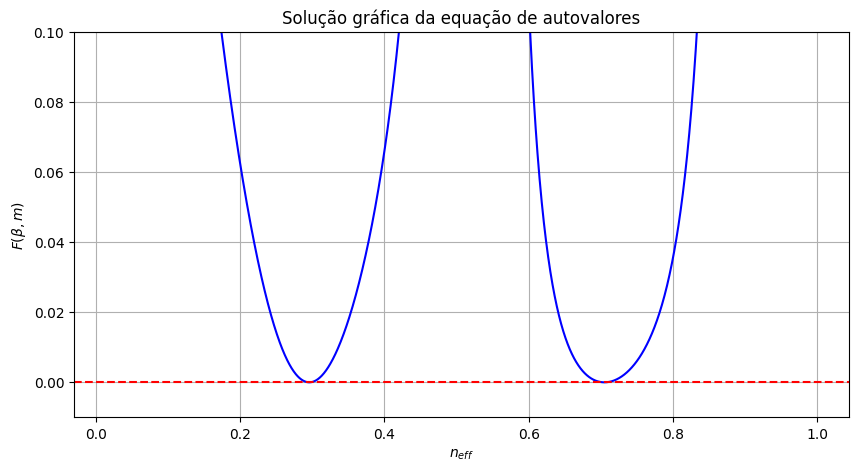

In [467]:
b_array = np.linspace(1.46001, 1.4799, 2001)*k0

m = 0

F_array = F(b_array, m)

# Identifica valores muito elevados
mask = np.abs(F_array) < 2

plt.figure(figsize=(10,5))
plt.plot((b_array[mask]/k0-n2)/(n1-n2), F_array[mask], color = 'blue')
plt.grid(True)
plt.ylim([-0.01, 0.1])
plt.axhline(0, color = 'red', linestyle = '--')
plt.xlabel(r'$n_{eff}$')
plt.ylabel(r'$F(\beta, m)$')
plt.title('Solução gráfica da equação de autovalores')
plt.show()

In [468]:
np.max(b_array[mask]/k0)

np.float64(1.4799)